# Random forest: will a Chicago traffic crash result in an injury?

Target: INJURIES_TOTAL > 0

Written to line up with logreg_crash_injury.py so the two can be compared directly:
same data loading, same leakage exclusions, same features, same split code and seed,
same metric functions, same thresholds, same bootstrap resamples, same subgroup /
robustness definitions, same permutation-importance sample. Only the model differs.

Usage:  python rf_crash_injury.py
Make CONFIG match the logistic regression script (same file, SPLIT_MODE, flags).

In [2]:
%matplotlib inline
%pip install scikit-learn pandas numpy matplotlib
import os
import time
import pickle
import hashlib
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
    matthews_corrcoef, roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    confusion_matrix, roc_curve, precision_recall_curve,
)

warnings.filterwarnings("ignore")

Note: you may need to restart the kernel to use updated packages.


## CONFIG

Keep the first block identical to the logistic regression script. Re-run this cell after changing anything here.

In [27]:
# --- keep these identical to the logistic regression script ---
DATA_PATH = "crashes.csv"   # <- change to your file name
SPLIT_MODE = "random"      # "random" or "temporal" (as in logreg); "year" = train earlier years,
                           # validate on second-to-last year, test on last year
USE_CONTRIBUTORY_CAUSE = False  # PRIM/SEC causes are assigned post-investigation; keep False
USE_CLASS_WEIGHT = False   # False keeps probabilities calibrated; True boosts recall
N_BOOT = 200
SEED = 42
# --- random forest only ---
TAG = "rf"                 # output file prefix, so nothing overwrites the logreg files
GRID = dict(min_samples_leaf=[10, 30, 100], max_depth=[None, 16], max_features=["sqrt", 0.3])
N_TREES_TUNE = 150
N_TREES_FINAL = 500
N_TREES_ABLATION = 100     # retrains in robustness / extras
N_JOBS = -1
RUN_EXTRAS = True          # RF-only extras at the end (tree-vote spread, seasonal and beat shift)
TUNE_FRAC = 0.25       # fraction of training rows used for tuning only (1.0 = use all rows)
GRID = dict(min_samples_leaf=[30, 100], max_depth=[None, 16], max_features=["sqrt", 0.3])
N_TREES_TUNE = 100
# ============================================================================
print(f"CPU cores available: {os.cpu_count()} (n_jobs={N_JOBS}); mention this when comparing train times")

CPU cores available: 8 (n_jobs=-1); mention this when comparing train times


## 1. LOAD

In [14]:
df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = [c.strip().upper() for c in df.columns]
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")

df = df[df["INJURIES_TOTAL"].notna()].copy()
df["y"] = (df["INJURIES_TOTAL"] > 0).astype(int)
print(f"Injury rate: {df['y'].mean():.3%}  (n={len(df):,})")

df["CRASH_DATE"] = pd.to_datetime(df["CRASH_DATE"], errors="coerce")
df = df[df["CRASH_DATE"].notna()].copy()

Loaded 405,144 rows, 49 columns
Injury rate: 16.596%  (n=404,199)


## 2. FEATURES

In [15]:
# Leakage excluded on purpose: INJURIES_*, MOST_SEVERE_INJURY, CRASH_TYPE (defines the
# label), DAMAGE, DATE_POLICE_NOTIFIED, REPORT_TYPE (all post-crash), plus ID/address cols.
df["HOUR_SIN"] = np.sin(2 * np.pi * df["CRASH_HOUR"] / 24)
df["HOUR_COS"] = np.cos(2 * np.pi * df["CRASH_HOUR"] / 24)
df["IS_WEEKEND"] = df["CRASH_DAY_OF_WEEK"].isin([1, 7]).astype(int)  # 1=Sun, 7=Sat

NUM_COLS = ["POSTED_SPEED_LIMIT", "LANE_CNT", "NUM_UNITS", "CRASH_HOUR",
            "HOUR_SIN", "HOUR_COS", "IS_WEEKEND", "CRASH_MONTH"]
CAT_COLS = ["TRAFFIC_CONTROL_DEVICE", "DEVICE_CONDITION", "WEATHER_CONDITION",
            "LIGHTING_CONDITION", "FIRST_CRASH_TYPE", "TRAFFICWAY_TYPE", "ALIGNMENT",
            "ROADWAY_SURFACE_COND", "ROAD_DEFECT", "INTERSECTION_RELATED_I",
            "NOT_RIGHT_OF_WAY_I", "HIT_AND_RUN_I", "CRASH_DAY_OF_WEEK"]
if USE_CONTRIBUTORY_CAUSE:
    CAT_COLS += ["PRIM_CONTRIBUTORY_CAUSE", "SEC_CONTRIBUTORY_CAUSE"]

skipped = [c for c in NUM_COLS + CAT_COLS if c not in df.columns]
if skipped:
    print("NOTE: these feature columns are not in your file and are skipped (check the logreg run skips the same):", skipped)
NUM_COLS = [c for c in NUM_COLS if c in df.columns]
CAT_COLS = [c for c in CAT_COLS if c in df.columns]
FEATURES = NUM_COLS + CAT_COLS
print("Features used:", FEATURES)

for c in NUM_COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
for c in CAT_COLS:
    df[c] = df[c].astype(str).replace({"nan": "MISSING", "": "MISSING"}).fillna("MISSING")

Features used: ['POSTED_SPEED_LIMIT', 'LANE_CNT', 'NUM_UNITS', 'CRASH_HOUR', 'HOUR_SIN', 'HOUR_COS', 'IS_WEEKEND', 'CRASH_MONTH', 'TRAFFIC_CONTROL_DEVICE', 'DEVICE_CONDITION', 'WEATHER_CONDITION', 'LIGHTING_CONDITION', 'FIRST_CRASH_TYPE', 'TRAFFICWAY_TYPE', 'ALIGNMENT', 'ROADWAY_SURFACE_COND', 'ROAD_DEFECT', 'INTERSECTION_RELATED_I', 'NOT_RIGHT_OF_WAY_I', 'HIT_AND_RUN_I', 'CRASH_DAY_OF_WEEK']


## 3. SPLIT

In [16]:
if SPLIT_MODE == "temporal":
    df = df.sort_values("CRASH_DATE").reset_index(drop=True)
    n = len(df)
    tr, va, te = df.iloc[:int(.6 * n)], df.iloc[int(.6 * n):int(.8 * n)], df.iloc[int(.8 * n):]
elif SPLIT_MODE == "year":
    yrs = df["CRASH_DATE"].dt.year
    last = yrs.max()
    tr, va, te = df[yrs < last - 1], df[yrs == last - 1], df[yrs == last]
else:
    tr, tmp = train_test_split(df, test_size=0.4, stratify=df["y"], random_state=SEED)
    va, te = train_test_split(tmp, test_size=0.5, stratify=tmp["y"], random_state=SEED)

X_tr, y_tr = tr[FEATURES], tr["y"].values
X_va, y_va = va[FEATURES], va["y"].values
X_te, y_te = te[FEATURES], te["y"].values
print(f"Split ({SPLIT_MODE}): train={len(tr):,} val={len(va):,} test={len(te):,}")
print("Test-set fingerprint (must match the logreg run):",
      hashlib.md5(np.asarray(te.index).tobytes()).hexdigest()[:8])
print(f"No-skill reference on test: accuracy={1 - y_te.mean():.3f}, PR-AUC={y_te.mean():.3f}")

Split (random): train=242,519 val=80,840 test=80,840
Test-set fingerprint (must match the logreg run): ab504b8b
No-skill reference on test: accuracy=0.834, PR-AUC=0.166


## 4. HELPERS

In [17]:
def build_pipe(n_estimators, num_cols, cat_cols, **rf_params):
    # Same preprocessing as the logreg script (scaling is harmless to trees; kept so inputs are identical).
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat_cols),
    ])
    clf = RandomForestClassifier(
        n_estimators=n_estimators, n_jobs=N_JOBS, random_state=SEED,
        class_weight="balanced_subsample" if USE_CLASS_WEIGHT else None, **rf_params)
    return Pipeline([("pre", pre), ("clf", clf)])


def ece_score(y, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, bins) - 1, 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return ece


def metrics(y, p, thr=0.5):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    yhat = (p >= thr).astype(int)
    return {
        "accuracy": accuracy_score(y, yhat),
        "precision": precision_score(y, yhat, zero_division=0),
        "recall": recall_score(y, yhat, zero_division=0),
        "f1": f1_score(y, yhat, zero_division=0),
        "balanced_acc": balanced_accuracy_score(y, yhat),
        "mcc": matthews_corrcoef(y, yhat),
        "roc_auc": roc_auc_score(y, p),
        "pr_auc": average_precision_score(y, p),
        "log_loss": log_loss(y, p),
        "brier": brier_score_loss(y, p),
        "ece": ece_score(y, p),
    }


def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return thr[np.argmax(f1)]


def recall_target_threshold(y, p, target=0.90):
    """Highest threshold that still achieves >= target recall."""
    _, rec, thr = precision_recall_curve(y, p)
    ok = np.where(rec[:-1] >= target)[0]
    return thr[ok[-1]] if len(ok) else thr[0]

## 5. TUNE HYPERPARAMETERS ON VALIDATION

This is the slowest cell (12 forests). Shrink `GRID` or `N_TREES_TUNE` in CONFIG for a quick run.

In [18]:
print("\n=== Hyperparameter tuning (validation log loss) ===")

# Tune on a random subsample of the training rows (the final model still trains on all of them)
if TUNE_FRAC < 1.0:
    pos = np.random.default_rng(SEED).choice(len(X_tr), size=int(TUNE_FRAC * len(X_tr)), replace=False)
    X_tune, y_tune = X_tr.iloc[pos], y_tr[pos]
else:
    X_tune, y_tune = X_tr, y_tr
print(f"Tuning on {len(X_tune):,} of {len(X_tr):,} training rows; scoring on {len(X_va):,} validation rows")

tune_rows = []
for leaf, depth, mf in itertools.product(GRID["min_samples_leaf"], GRID["max_depth"], GRID["max_features"]):
    t0 = time.perf_counter()
    pipe = build_pipe(N_TREES_TUNE, NUM_COLS, CAT_COLS,
                      min_samples_leaf=leaf, max_depth=depth, max_features=mf).fit(X_tune, y_tune)
    ll = log_loss(y_va, np.clip(pipe.predict_proba(X_va)[:, 1], 1e-7, 1 - 1e-7))
    tune_rows.append(dict(min_samples_leaf=leaf, max_depth=depth, max_features=mf,
                          val_log_loss=ll, fit_s=round(time.perf_counter() - t0, 1)))
    print(f"leaf={leaf:<4} depth={str(depth):<5} max_features={str(mf):<5} val log loss={ll:.4f}  ({tune_rows[-1]['fit_s']}s)")
tune_df = pd.DataFrame(tune_rows).sort_values("val_log_loss")
tune_df.to_csv(f"{TAG}_tuning.csv", index=False)
b = tune_df.iloc[0]
BEST = dict(min_samples_leaf=int(b["min_samples_leaf"]),
            max_depth=None if pd.isna(b["max_depth"]) else int(b["max_depth"]),
            max_features=b["max_features"] if isinstance(b["max_features"], str) else float(b["max_features"]))
print("Best params:", BEST)


=== Hyperparameter tuning (validation log loss) ===
Tuning on 60,629 of 242,519 training rows; scoring on 80,840 validation rows
leaf=30   depth=None  max_features=sqrt  val log loss=0.3554  (2.6s)
leaf=30   depth=None  max_features=0.3   val log loss=0.3478  (9.9s)
leaf=30   depth=16    max_features=sqrt  val log loss=0.3569  (3.8s)
leaf=30   depth=16    max_features=0.3   val log loss=0.3475  (9.7s)
leaf=100  depth=None  max_features=sqrt  val log loss=0.3631  (3.2s)
leaf=100  depth=None  max_features=0.3   val log loss=0.3488  (8.1s)
leaf=100  depth=16    max_features=sqrt  val log loss=0.3656  (3.0s)
leaf=100  depth=16    max_features=0.3   val log loss=0.3489  (7.4s)
Best params: {'min_samples_leaf': 30, 'max_depth': 16, 'max_features': 0.3}


## 6. FINAL FIT + EFFICIENCY

In [19]:
t0 = time.perf_counter()
model = build_pipe(N_TREES_FINAL, NUM_COLS, CAT_COLS, **BEST).fit(X_tr, y_tr)
train_time = time.perf_counter() - t0

t0 = time.perf_counter()
p_te = model.predict_proba(X_te)[:, 1]
infer_time = time.perf_counter() - t0
p_va = model.predict_proba(X_va)[:, 1]
p_tr = model.predict_proba(X_tr)[:, 1]

size_kb = len(pickle.dumps(model)) / 1024
print("\n=== Computational efficiency ===")
print(f"Train time: {train_time:.2f}s | Inference: {1000 * infer_time / len(X_te) * 1000:.3f} ms per 1,000 rows "
      f"| Model size: {size_kb:.1f} KB ({size_kb / 1024:.1f} MB)")


=== Computational efficiency ===
Train time: 395.73s | Inference: 15.511 ms per 1,000 rows | Model size: 96041.0 KB (93.8 MB)


## 7. THRESHOLDS (CHOSEN ON VALIDATION)

In [20]:
thr_f1 = best_f1_threshold(y_va, p_va)
thr_rec90 = recall_target_threshold(y_va, p_va, 0.90)
thresholds = {"default_0.5": 0.5, "max_F1": thr_f1, "recall>=0.90": thr_rec90}
print("\nThresholds picked on validation:", {k: round(float(v), 3) for k, v in thresholds.items()})


Thresholds picked on validation: {'default_0.5': 0.5, 'max_F1': 0.246, 'recall>=0.90': 0.104}


## 8. MAIN METRICS + GENERALIZATION

In [21]:
print("\n=== Test-set metrics at each threshold ===")
rows = {name: metrics(y_te, p_te, t) for name, t in thresholds.items()}
print(pd.DataFrame(rows).T.round(4).to_string())

print("\n=== Generalization (train / val / test at max-F1 threshold) ===")
gen = pd.DataFrame({
    "train": metrics(y_tr, p_tr, thr_f1),
    "val": metrics(y_va, p_va, thr_f1),
    "test": metrics(y_te, p_te, thr_f1),
}).T
print(gen[["accuracy", "f1", "roc_auc", "pr_auc", "log_loss"]].round(4).to_string())

print("\n=== Confusion matrix (test, max-F1 threshold) [rows=true, cols=pred] ===")
print(confusion_matrix(y_te, (p_te >= thr_f1).astype(int)))


=== Test-set metrics at each threshold ===
              accuracy  precision  recall      f1  balanced_acc     mcc  roc_auc  pr_auc  log_loss   brier     ece
default_0.5     0.8656     0.7790  0.2659  0.3964        0.6254  0.4038   0.8083  0.5429    0.3456  0.1047  0.0043
max_F1          0.8204     0.4641  0.5328  0.4961        0.7052  0.3888   0.8083  0.5429    0.3456  0.1047  0.0043
recall>=0.90    0.5450     0.2539  0.8983  0.3958        0.6865  0.2818   0.8083  0.5429    0.3456  0.1047  0.0043

=== Generalization (train / val / test at max-F1 threshold) ===
       accuracy      f1  roc_auc  pr_auc  log_loss
train    0.8291  0.5184   0.8279  0.5743    0.3343
val      0.8231  0.4988   0.8097  0.5447    0.3449
test     0.8204  0.4961   0.8083  0.5429    0.3456

=== Confusion matrix (test, max-F1 threshold) [rows=true, cols=pred] ===
[[59171  8253]
 [ 6268  7148]]


## 9. BOOTSTRAP CIs

In [22]:
print(f"\n=== Bootstrap 95% CIs ({N_BOOT} resamples, test set) ===")
rng = np.random.default_rng(SEED)
boot = {"roc_auc": [], "pr_auc": [], "log_loss": [], "f1": [], "recall": []}
for _ in range(N_BOOT):
    i = rng.integers(0, len(y_te), len(y_te))
    yb, pb = y_te[i], p_te[i]
    if yb.min() == yb.max():
        continue
    m = metrics(yb, pb, thr_f1)
    for k in boot:
        boot[k].append(m[k])
for k, v in boot.items():
    lo, hi = np.percentile(v, [2.5, 97.5])
    print(f"{k:<9} {np.mean(v):.4f}  [{lo:.4f}, {hi:.4f}]")


=== Bootstrap 95% CIs (200 resamples, test set) ===
roc_auc   0.8082  [0.8034, 0.8119]
pr_auc    0.5424  [0.5351, 0.5511]
log_loss  0.3455  [0.3412, 0.3495]
f1        0.4958  [0.4883, 0.5028]
recall    0.5326  [0.5236, 0.5402]


## 10. CALIBRATION

In [23]:
# Calibrators are fit on VALIDATION predictions, evaluated on TEST.
print("\n=== Calibration (fit on validation, evaluated on test) ===")
logit = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
platt = LogisticRegression(C=1e6).fit(logit(p_va).reshape(-1, 1), y_va)
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_va, y_va)
p_platt = platt.predict_proba(logit(p_te).reshape(-1, 1))[:, 1]
p_iso = iso.predict(p_te)
calib = pd.DataFrame({
    "uncalibrated": metrics(y_te, p_te, thr_f1),
    "platt": metrics(y_te, p_platt, thr_f1),
    "isotonic": metrics(y_te, p_iso, thr_f1),
}).T
print(calib[["log_loss", "brier", "ece", "roc_auc", "pr_auc"]].round(4).to_string())


=== Calibration (fit on validation, evaluated on test) ===
              log_loss   brier     ece  roc_auc  pr_auc
uncalibrated    0.3456  0.1047  0.0043   0.8083  0.5429
platt           0.3456  0.1047  0.0024   0.8083  0.5429
isotonic        0.3460  0.1047  0.0028   0.8082  0.5355


## 11. SUBGROUP PERFORMANCE

In [24]:
print("\n=== Subgroup performance (test, max-F1 threshold) ===")
te_eval = te.copy()
te_eval["p"] = p_te
te_eval["SPEED_BIN"] = pd.cut(te_eval["POSTED_SPEED_LIMIT"], [-1, 25, 30, 35, 100],
                              labels=["<=25", "26-30", "31-35", ">35"]).astype(str)
te_eval["TIME_OF_DAY"] = pd.cut(te_eval["CRASH_HOUR"], [-1, 5, 11, 17, 23],
                                labels=["night", "morning", "afternoon", "evening"]).astype(str)
te_eval["WEEKEND"] = te_eval["IS_WEEKEND"].map({0: "weekday", 1: "weekend"})

sub_rows = []
for col in ["LIGHTING_CONDITION", "WEATHER_CONDITION", "SPEED_BIN", "TIME_OF_DAY", "WEEKEND"]:
    for g, d in te_eval.groupby(col):
        if len(d) < 200:
            continue
        yy, pp = d["y"].values, d["p"].values
        yh = (pp >= thr_f1).astype(int)
        sub_rows.append({
            "feature": col, "group": g, "n": len(d), "injury_rate": yy.mean(),
            "mean_pred": pp.mean(),
            "recall": recall_score(yy, yh, zero_division=0),
            "precision": precision_score(yy, yh, zero_division=0),
            "roc_auc": roc_auc_score(yy, pp) if yy.min() != yy.max() else np.nan,
            "ece": ece_score(yy, pp),
        })
sub = pd.DataFrame(sub_rows)
print(sub.round(3).to_string(index=False))
sub.to_csv(f"{TAG}_subgroup_results.csv", index=False)


=== Subgroup performance (test, max-F1 threshold) ===
           feature                  group     n  injury_rate  mean_pred  recall  precision  roc_auc   ece
LIGHTING_CONDITION               DARKNESS  3578        0.159      0.164   0.537      0.466    0.809 0.007
LIGHTING_CONDITION DARKNESS, LIGHTED ROAD 18374        0.205      0.203   0.615      0.432    0.793 0.006
LIGHTING_CONDITION                   DAWN  1346        0.198      0.187   0.545      0.483    0.792 0.017
LIGHTING_CONDITION               DAYLIGHT 54245        0.154      0.155   0.494      0.482    0.808 0.004
LIGHTING_CONDITION                   DUSK  2184        0.173      0.176   0.556      0.477    0.814 0.010
LIGHTING_CONDITION                UNKNOWN  1113        0.056      0.078   0.548      0.567    0.891 0.029
 WEATHER_CONDITION                  CLEAR 68042        0.164      0.164   0.536      0.470    0.813 0.005
 WEATHER_CONDITION        CLOUDY/OVERCAST  2570        0.165      0.164   0.537      0.491    0.8

## 12. ROBUSTNESS

In [28]:
print("\n=== Robustness (test set) ===")
rob = {"clean": metrics(y_te, p_te, thr_f1)}

# (a) Inject missing values at 10/30/50%
for frac in [0.1, 0.3, 0.5]:
    Xm = X_te.copy()
    r = np.random.default_rng(SEED)
    for c in CAT_COLS:
        Xm.loc[r.random(len(Xm)) < frac, c] = "MISSING"
    for c in [c for c in ["POSTED_SPEED_LIMIT", "LANE_CNT", "CRASH_HOUR"] if c in Xm.columns]:
        Xm.loc[r.random(len(Xm)) < frac, c] = np.nan
    rob[f"missing_{int(frac * 100)}%"] = metrics(y_te, model.predict_proba(Xm)[:, 1], thr_f1)

# (b) Gaussian noise on numeric features (scaled to each feature's std)
for s in [0.25, 0.5, 1.0]:
    Xn = X_te.copy()
    r = np.random.default_rng(SEED)
    for c in [c for c in ["POSTED_SPEED_LIMIT", "CRASH_HOUR", "NUM_UNITS"] if c in Xn.columns]:
        Xn[c] = Xn[c] + r.normal(0, s * X_tr[c].std(), len(Xn))
    rob[f"noise_{s}sd"] = metrics(y_te, model.predict_proba(Xn)[:, 1], thr_f1)

# (c) Drop feature groups and retrain
groups = {
    "no_weather": ["WEATHER_CONDITION", "ROADWAY_SURFACE_COND", "ROAD_DEFECT"],
    "no_lighting": ["LIGHTING_CONDITION"],
    "no_time": ["CRASH_HOUR", "HOUR_SIN", "HOUR_COS", "IS_WEEKEND", "CRASH_MONTH", "CRASH_DAY_OF_WEEK"],
    "no_crash_type": ["FIRST_CRASH_TYPE"],
}
for name, drop in groups.items():
    nc = [c for c in NUM_COLS if c not in drop]
    cc = [c for c in CAT_COLS if c not in drop]
    m2 = build_pipe(N_TREES_ABLATION, nc, cc, **BEST).fit(X_tr[nc + cc], y_tr)
    rob[f"drop_{name}"] = metrics(y_te, m2.predict_proba(X_te[nc + cc])[:, 1], thr_f1)

rob_df = pd.DataFrame(rob).T
print(rob_df[["accuracy", "f1", "recall", "roc_auc", "pr_auc", "log_loss", "ece"]].round(4).to_string())
rob_df.to_csv(f"{TAG}_robustness_results.csv")


=== Robustness (test set) ===
                    accuracy      f1  recall  roc_auc  pr_auc  log_loss     ece
clean                 0.8204  0.4961  0.5328   0.8083  0.5429    0.3456  0.0043
missing_10%           0.8187  0.4699  0.4842   0.7923  0.5173    0.3557  0.0046
missing_30%           0.8174  0.4161  0.3922   0.7584  0.4625    0.3760  0.0099
missing_50%           0.8158  0.3572  0.3084   0.7207  0.4056    0.3955  0.0149
noise_0.25sd          0.8176  0.4948  0.5382   0.8080  0.5426    0.3457  0.0044
noise_0.5sd           0.8100  0.4873  0.5442   0.8050  0.5375    0.3475  0.0046
noise_1.0sd           0.7615  0.4469  0.5804   0.7841  0.5093    0.3612  0.0230
drop_no_weather       0.8199  0.4947  0.5312   0.8067  0.5409    0.3464  0.0039
drop_no_lighting      0.8201  0.4963  0.5339   0.8080  0.5423    0.3458  0.0039
drop_no_time          0.8191  0.4948  0.5338   0.8075  0.5422    0.3459  0.0030
drop_no_crash_type    0.7562  0.3671  0.4260   0.6972  0.3158    0.4139  0.0019


## 13. UNCERTAINTY

In [29]:
print("\n=== Uncertainty ===")
pc = np.clip(p_te, 1e-7, 1 - 1e-7)
entropy = -(pc * np.log2(pc) + (1 - pc) * np.log2(1 - pc))
correct = ((p_te >= thr_f1).astype(int) == y_te)
print(f"Mean predictive entropy (bits): correct={entropy[correct].mean():.3f} | incorrect={entropy[~correct].mean():.3f}")
conf = np.maximum(p_te, 1 - p_te)
print(f"Mean confidence: correct={conf[correct].mean():.3f} | incorrect={conf[~correct].mean():.3f}")
print("Accuracy by confidence quartile:")
q = pd.qcut(conf, 4, duplicates="drop")
print(pd.DataFrame({"correct": correct, "q": q}).groupby("q").correct.agg(["mean", "size"]).round(3).to_string())


=== Uncertainty ===
Mean predictive entropy (bits): correct=0.452 | incorrect=0.746
Mean confidence: correct=0.887 | incorrect=0.760
Accuracy by confidence quartile:
                 mean   size
q                           
(0.499, 0.812]  0.531  20210
(0.812, 0.877]  0.854  20210
(0.877, 0.952]  0.922  20210
(0.952, 0.999]  0.975  20210


## 14. INTERPRETABILITY

In [30]:
rf = model.named_steps["clf"]
print("\n=== Top random forest importances (impurity, one-hot level) ===")
names = model.named_steps["pre"].get_feature_names_out()
imp_df = pd.DataFrame({"feature": names, "importance": rf.feature_importances_}).sort_values("importance", ascending=False)
print(imp_df.head(15).round(4).to_string(index=False))
imp_df.to_csv(f"{TAG}_importance.csv", index=False)

print("\n=== Permutation importance (original columns, PR-AUC drop, 20k test sample) ===")
samp = np.random.default_rng(SEED).choice(len(X_te), size=min(20000, len(X_te)), replace=False)
pi = permutation_importance(model, X_te.iloc[samp], y_te[samp], scoring="average_precision",
                            n_repeats=3, random_state=SEED, n_jobs=N_JOBS)
pi_df = pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean,
                      "std": pi.importances_std}).sort_values("importance", ascending=False)
print(pi_df.round(4).to_string(index=False))
pi_df.to_csv(f"{TAG}_permutation_importance.csv", index=False)


=== Top random forest importances (impurity, one-hot level) ===
                                       feature  importance
              cat__FIRST_CRASH_TYPE_PEDESTRIAN      0.3629
            cat__FIRST_CRASH_TYPE_PEDALCYCLIST      0.1692
                                num__NUM_UNITS      0.0666
           cat__INTERSECTION_RELATED_I_MISSING      0.0569
    cat__FIRST_CRASH_TYPE_PARKED MOTOR VEHICLE      0.0444
                 cat__INTERSECTION_RELATED_I_Y      0.0394
cat__FIRST_CRASH_TYPE_SIDESWIPE SAME DIRECTION      0.0369
                   cat__FIRST_CRASH_TYPE_ANGLE      0.0208
                               num__CRASH_HOUR      0.0151
                                 num__HOUR_COS      0.0140
                              num__CRASH_MONTH      0.0135
                cat__FIRST_CRASH_TYPE_REAR END      0.0126
                          cat__HIT_AND_RUN_I_Y      0.0108
                       num__POSTED_SPEED_LIMIT      0.0107
                 cat__TRAFFICWAY_TYPE_FOUR WAY    

## 15. SAVE PREDICTIONS

In [31]:
# Same rows, one column per model, so the final comparison can be built from files.
out = pd.DataFrame({"y_true": y_te, f"p_{TAG}": p_te, f"p_{TAG}_platt": p_platt, f"p_{TAG}_isotonic": p_iso},
                   index=te.index)
if "CRASH_RECORD_ID" in te.columns:
    out.insert(0, "CRASH_RECORD_ID", te["CRASH_RECORD_ID"].values)
out.to_csv(f"{TAG}_test_predictions.csv", index_label="row_index")

## 16. PLOTS

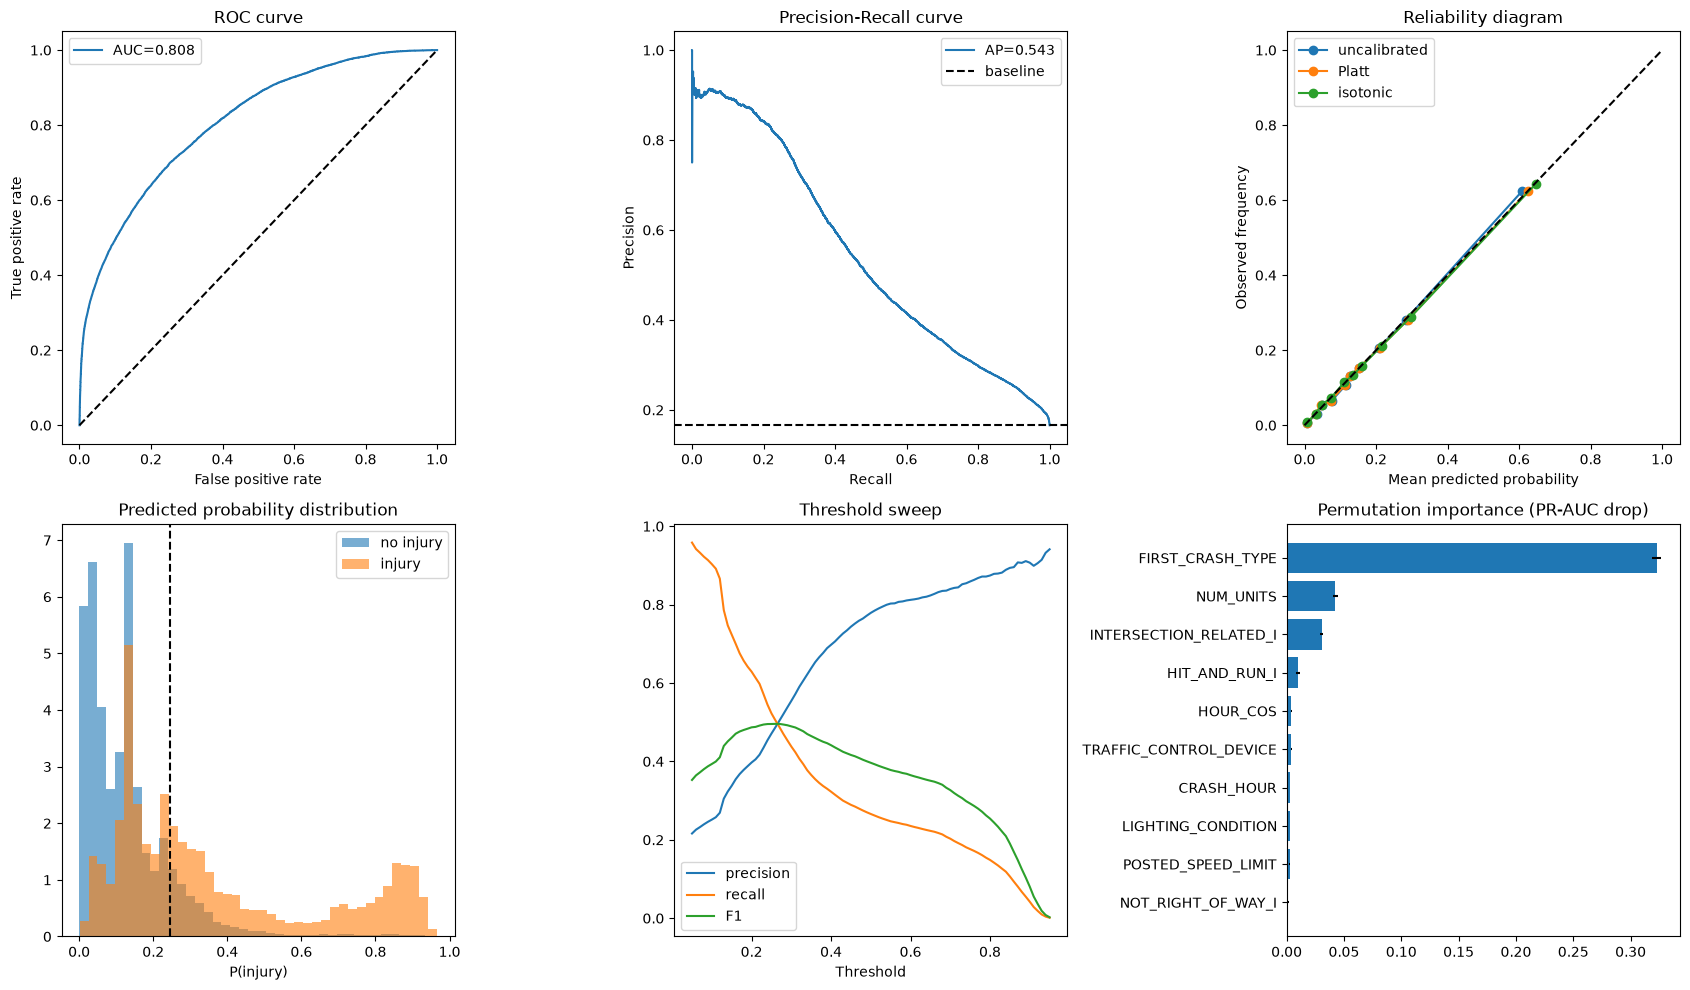


Saved: rf_evaluation.png, rf_test_predictions.csv, rf_subgroup_results.csv, rf_robustness_results.csv, rf_importance.csv, rf_permutation_importance.csv, rf_tuning.csv


In [32]:
fig, ax = plt.subplots(2, 3, figsize=(17, 10))

fpr, tpr, _ = roc_curve(y_te, p_te)
ax[0, 0].plot(fpr, tpr, label=f"AUC={roc_auc_score(y_te, p_te):.3f}")
ax[0, 0].plot([0, 1], [0, 1], "k--")
ax[0, 0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
ax[0, 0].legend()

prec, rec, _ = precision_recall_curve(y_te, p_te)
ax[0, 1].plot(rec, prec, label=f"AP={average_precision_score(y_te, p_te):.3f}")
ax[0, 1].axhline(y_te.mean(), color="k", ls="--", label="baseline")
ax[0, 1].set(title="Precision-Recall curve", xlabel="Recall", ylabel="Precision")
ax[0, 1].legend()

for lbl, pp in [("uncalibrated", p_te), ("Platt", p_platt), ("isotonic", p_iso)]:
    fr, mp = calibration_curve(y_te, pp, n_bins=10, strategy="quantile")
    ax[0, 2].plot(mp, fr, "o-", label=lbl)
ax[0, 2].plot([0, 1], [0, 1], "k--")
ax[0, 2].set(title="Reliability diagram", xlabel="Mean predicted probability", ylabel="Observed frequency")
ax[0, 2].legend()

ax[1, 0].hist(p_te[y_te == 0], bins=40, alpha=.6, label="no injury", density=True)
ax[1, 0].hist(p_te[y_te == 1], bins=40, alpha=.6, label="injury", density=True)
ax[1, 0].axvline(thr_f1, color="k", ls="--")
ax[1, 0].set(title="Predicted probability distribution", xlabel="P(injury)")
ax[1, 0].legend()

ths = np.linspace(0.05, 0.95, 91)
ax[1, 1].plot(ths, [precision_score(y_te, p_te >= t, zero_division=0) for t in ths], label="precision")
ax[1, 1].plot(ths, [recall_score(y_te, p_te >= t) for t in ths], label="recall")
ax[1, 1].plot(ths, [f1_score(y_te, p_te >= t) for t in ths], label="F1")
ax[1, 1].set(title="Threshold sweep", xlabel="Threshold")
ax[1, 1].legend()

top = pi_df.head(10).iloc[::-1]
ax[1, 2].barh(top["feature"], top["importance"], xerr=top["std"])
ax[1, 2].set(title="Permutation importance (PR-AUC drop)")

plt.tight_layout()
plt.savefig(f"{TAG}_evaluation.png", dpi=150)
plt.show()
print(f"\nSaved: {TAG}_evaluation.png, {TAG}_test_predictions.csv, {TAG}_subgroup_results.csv, "
      f"{TAG}_robustness_results.csv, {TAG}_importance.csv, {TAG}_permutation_importance.csv, {TAG}_tuning.csv")

## 17. RF-ONLY EXTRAS

Not in the logistic regression script. Everything above is the like-for-like comparison.

In [33]:
# Not in the logistic regression script. Everything above is the like-for-like comparison.
if RUN_EXTRAS:
    print("\n=== RF extras ===")
    # (a) Tree-vote spread: disagreement among individual trees
    Xt = model.named_steps["pre"].transform(X_te.iloc[samp])
    tree_p = np.stack([t.predict_proba(Xt)[:, 1] for t in rf.estimators_[:200]])
    spread = tree_p.std(axis=0)
    cs = correct[samp]
    print(f"Tree-vote spread: correct={spread[cs].mean():.3f} | incorrect={spread[~cs].mean():.3f}")
    qs = pd.qcut(spread, 4, duplicates="drop")
    print("Error rate by spread quartile:")
    print(pd.DataFrame({"error_rate": ~cs, "q": qs}).groupby("q").error_rate.agg(["mean", "size"]).round(3).to_string())

    # (b) Seasonal shift: train on warm months only, test on warm vs winter
    shift = {"test (reference)": metrics(y_te, p_te, thr_f1)}
    warm = [4, 5, 6, 7, 8, 9, 10]
    tr_w = tr[tr["CRASH_MONTH"].isin(warm)]
    te_w, te_c = te[te["CRASH_MONTH"].isin(warm)], te[~te["CRASH_MONTH"].isin(warm)]
    if len(te_w) and len(te_c) and te_c["y"].nunique() == 2:
        m_s = build_pipe(N_TREES_ABLATION, NUM_COLS, CAT_COLS, **BEST).fit(tr_w[FEATURES], tr_w["y"].values)
        for lbl, d in [("warm->warm (in-distribution)", te_w), ("warm->winter (shifted)", te_c)]:
            shift[lbl] = metrics(d["y"].values, m_s.predict_proba(d[FEATURES])[:, 1], thr_f1)

    # (c) Spatial shift: hold out 25% of police beats from training
    if "BEAT_OF_OCCURRENCE" in df.columns:
        beats = df["BEAT_OF_OCCURRENCE"].dropna().unique()
        held = set(np.random.default_rng(SEED).choice(beats, size=max(1, int(0.25 * len(beats))), replace=False))
        tr_b = tr[~tr["BEAT_OF_OCCURRENCE"].isin(held)]
        te_seen, te_held = te[~te["BEAT_OF_OCCURRENCE"].isin(held)], te[te["BEAT_OF_OCCURRENCE"].isin(held)]
        if len(te_seen) and len(te_held):
            m_b = build_pipe(N_TREES_ABLATION, NUM_COLS, CAT_COLS, **BEST).fit(tr_b[FEATURES], tr_b["y"].values)
            for lbl, d in [("seen beats", te_seen), ("held-out beats (shifted)", te_held)]:
                shift[lbl] = metrics(d["y"].values, m_b.predict_proba(d[FEATURES])[:, 1], thr_f1)

    shift_df = pd.DataFrame(shift).T
    print(shift_df[["accuracy", "f1", "recall", "precision", "roc_auc", "pr_auc", "log_loss", "ece"]].round(4).to_string())
    shift_df.to_csv(f"{TAG}_shift_results.csv")


=== RF extras ===
Tree-vote spread: correct=0.044 | incorrect=0.076
Error rate by spread quartile:
                                  mean  size
q                                           
(0.0010899999999999998, 0.0211]  0.053  5000
(0.0211, 0.042]                  0.094  5000
(0.042, 0.0716]                  0.179  5000
(0.0716, 0.238]                  0.387  5000
                              accuracy      f1  recall  precision  roc_auc  pr_auc  log_loss     ece
test (reference)                0.8204  0.4961  0.5328     0.4641   0.8083  0.5429    0.3456  0.0043
warm->warm (in-distribution)    0.8139  0.5089  0.5587     0.4672   0.8122  0.5545    0.3516  0.0048
warm->winter (shifted)          0.8090  0.4668  0.5389     0.4117   0.7970  0.5114    0.3390  0.0149
seen beats                      0.8171  0.4961  0.5426     0.4570   0.8092  0.5421    0.3456  0.0051
held-out beats (shifted)        0.8158  0.4899  0.5332     0.4532   0.8027  0.5384    0.3482  0.0050


In [34]:
pd.DataFrame({name: metrics(y_te, p_te, t) for name, t in thresholds.items()}).T.to_csv(f"{TAG}_test_metrics_by_threshold.csv")
gen.to_csv(f"{TAG}_generalization.csv")
calib.to_csv(f"{TAG}_calibration.csv")
pd.DataFrame({k: [np.mean(v), *np.percentile(v, [2.5, 97.5])] for k, v in boot.items()},
             index=["mean", "ci_low", "ci_high"]).T.to_csv(f"{TAG}_bootstrap.csv")
pd.Series({
    "train_time_s": train_time,
    "inference_ms_per_1000_rows": 1000 * infer_time / len(X_te) * 1000,
    "model_size_kb": size_kb,
    "cpu_cores": os.cpu_count(),
    "n_trees": N_TREES_FINAL,
    **BEST,
    "threshold_max_f1": thr_f1,
    "threshold_recall90": thr_rec90,
    "test_rows": len(y_te),
    "test_fingerprint": hashlib.md5(np.asarray(te.index).tobytes()).hexdigest()[:8],
}).to_csv(f"{TAG}_run_info.csv", header=["value"])
print("saved summary files")

saved summary files


In [3]:
print(pd.read_csv("rf_run_info.csv", index_col=0))
print(pd.read_csv("rf_tuning.csv"))

                                          value
train_time_s                  395.7265885419911
inference_ms_per_1000_rows   15.511408337247444
model_size_kb                  96040.9560546875
cpu_cores                                     8
n_trees                                     500
min_samples_leaf                             30
max_depth                                    16
max_features                                0.3
threshold_max_f1            0.24563274986802017
threshold_recall90          0.10404498012384585
test_rows                                 80840
test_fingerprint                       ab504b8b
   min_samples_leaf  max_depth max_features  val_log_loss  fit_s
0                30       16.0          0.3      0.347471    9.7
1                30        NaN          0.3      0.347838    9.9
2               100        NaN          0.3      0.348782    8.1
3               100       16.0          0.3      0.348891    7.4
4                30        NaN         sqrt      0.